# Data Challenge 2026–2027 · EasyVista — SLA prediction in ITSM
## Exploratory analysis

The two tasks of the challenge:
1. **Classification**: will the ticket's SLA be violated?
2. **Regression**: how long will it take to resolve the ticket?

This notebook stops at the exploratory analysis:
1. Loading and cleaning
2. Target definition and first plots (violation rate over time, resolution-time distribution, violation rate by urgency)


**Requirements:** `pandas numpy matplotlib holidays`

### Setup (Colab)
Run these two cells first. The first one writes `prep.py` (shared data preparation) into the working folder, so you do not need to upload it. The second installs the missing libraries and asks you to upload `raw_EV_data_challenge.csv`.

In [1]:
%%writefile prep.py
"""Shared data preparation for the EasyVista Data Challenge (SLA prediction).

Usage:
    from prep import load_data, CAT_CREATE, NUM_CREATE, ...
    df = load_data("raw_EV_data_challenge.csv")

Changes vs. the first version (see the work guide, section 3):
  * calendar features use Paris local time instead of UTC                     (issue 5)
  * `sla_nominal`: deadline length known at submission, replaces the
    recorded `sla_real_hours`, which looks recomputed during the ticket life (issue 1)
  * `open_recent_30d`: alternative load counter on the last 30 days only (issue 3).
    The rolling CV prefers the original cumulative counter, so it stays in NUM_CREATE
    and the 30-day version is kept in RECENT_LOAD for the ablation
  * `never_closed` flag, to report metrics with and without these tickets    (issue 4)
"""
import numpy as np
import pandas as pd
import holidays

DATE_COLS = ["SUBMIT_DATE_UT", "MAX_RESOLUTION_DATE_UT", "END_DATE_UT"]
VALID_START = pd.Timestamp("2024-01-01")
TEST_START = pd.Timestamp("2024-04-01")
REG_TEST_END = pd.Timestamp("2024-08-01")   # margin against censoring for the "plain" regression test
LOCAL_TZ = "Europe/Paris"                   # timestamps are UTC; business hours follow Paris time
LOAD_WINDOW_DAYS = 30                       # look-back window for the load feature

# Features known when the ticket is created (no leakage)
CAT_CREATE = ["SD_CATALOG_PATH_EN", "URGENCY_VALUE", "IMPACT_VALUE", "SLA_DELAY", "REQUEST_ORIGIN", "SUBMITTED_BY_ID"]
NUM_CREATE = ["sla_nominal", "hour", "dow", "month", "is_weekend", "is_holiday", "off_hours",
              "submitter_missing", "open_tickets_at_submit", "open_same_type_at_submit",
              "arrivals_24h", "arrivals_7d", "submitter_prev_tickets"]

# Kept only for ablations
LEAK_SUSPECT = ["sla_real_hours"]                                  # recorded deadline length (likely leak)
RECENT_LOAD = ["open_recent_30d", "open_recent_30d_same_type"]     # 30-day load counters (no time trend)
CUMULATIVE_LOAD = ["open_tickets_at_submit", "open_same_type_at_submit"]  # in NUM_CREATE; trends with time

# "Oracle" features, known only after the ticket is closed (upper bound, never for production)
CAT_ORACLE = ["LAST_DONE_BY_ID", "STATUS_EN"]
NUM_ORACLE = ["nb_actions"]

MIN_HOURS = 1 / 60  # 1 minute: minimum duration, avoids log(0) in survival models


def load_data(path):
    df = pd.read_csv(path, sep=";", na_values=["NULL"])
    for c in DATE_COLS:
        df[c] = pd.to_datetime(df[c]).astype("datetime64[ns]")
    df = df.sort_values("SUBMIT_DATE_UT").reset_index(drop=True)

    # Impossible closing dates (before submission, e.g. 1900-01-01) -> missing
    df.loc[df["END_DATE_UT"] < df["SUBMIT_DATE_UT"], "END_DATE_UT"] = pd.NaT
    extract = max(df["SUBMIT_DATE_UT"].max(), df["END_DATE_UT"].max())
    df.attrs["extract_date"] = extract

    # Targets, as known at the extraction date
    df["viol"] = viol_as_of(df, extract)
    df["res_hours"] = (df["END_DATE_UT"] - df["SUBMIT_DATE_UT"]).dt.total_seconds() / 3600
    df["never_closed"] = df["END_DATE_UT"].isna().astype(int)

    t = df["SUBMIT_DATE_UT"]
    df["split"] = np.where(t < VALID_START, "train", np.where(t < TEST_START, "valid", "test"))
    _add_features(df)
    return df


def viol_as_of(df, cutoff):
    """SLA-violation label as it would have been known at date `cutoff`.
    1   = deadline passed without closure (or closed after the deadline), known if deadline < cutoff
    0   = closed within the deadline, known if closure <= cutoff
    NaN = still unknown at that date (or ticket without SLA)."""
    end, dl = df["END_DATE_UT"], df["MAX_RESOLUTION_DATE_UT"]
    out = pd.Series(np.nan, index=df.index)
    ok0 = dl.notna() & end.notna() & (end <= dl) & (end <= cutoff)
    ok1 = dl.notna() & (dl < cutoff) & (end.isna() | (end > dl))
    out[ok0] = 0.0
    out[ok1] = 1.0
    return out


def duration_as_of(df, cutoff):
    """Duration in hours and event indicator as known at date `cutoff`.
    Tickets not closed by `cutoff` are right-censored at (cutoff - submission)."""
    end = df["END_DATE_UT"]
    observed = end.notna() & (end <= cutoff)
    stop = end.where(observed, cutoff)
    dur = ((stop - df["SUBMIT_DATE_UT"]).dt.total_seconds() / 3600).clip(lower=MIN_HOURS)
    return dur, observed.astype(int)


def _open_recent(sub_ns, end_ns, window_ns):
    """For each ticket: how many tickets submitted in the previous `window_ns` are still open at its submission.
    Arrays must be sorted by submission time. Uses only information available at submission."""
    first = np.searchsorted(sub_ns, sub_ns - window_ns, side="left")
    before = np.searchsorted(sub_ns, sub_ns, side="left")
    out = np.empty(len(sub_ns), dtype=np.int64)
    for i in range(len(sub_ns)):
        out[i] = np.count_nonzero(end_ns[first[i]:before[i]] >= sub_ns[i])
    return out


def _add_features(df):
    t = df["SUBMIT_DATE_UT"]

    # Recorded deadline length (suspected leakage: kept only for ablations)
    df["sla_real_hours"] = (df["MAX_RESOLUTION_DATE_UT"] - t).dt.total_seconds() / 3600

    # Calendar features in Paris local time (handles daylight saving)
    loc = t.dt.tz_localize("UTC").dt.tz_convert(LOCAL_TZ).dt.tz_localize(None)
    df["hour"] = loc.dt.hour
    df["dow"] = loc.dt.dayofweek
    df["month"] = loc.dt.month
    df["is_weekend"] = (df["dow"] >= 5).astype(int)
    fr = holidays.France(years=range(loc.dt.year.min(), loc.dt.year.max() + 1))
    df["is_holiday"] = loc.dt.date.map(lambda d: d in fr).astype(int)
    df["off_hours"] = ((df["hour"] < 8) | (df["hour"] >= 18) | (df["is_weekend"] == 1)
                       | (df["is_holiday"] == 1)).astype(int)
    df["submitter_missing"] = df["SUBMITTED_BY_ID"].isna().astype(int)

    # Nominal deadline length, known at submission: median recorded length for the same
    # SLA_DELAY and hour of the week, estimated on the training period only
    # (a missing SLA_DELAY is treated as its own group: ~130 tickets have a deadline but no SLA_DELAY).
    # The median is robust to the ~9% of deadlines that are extended later on.
    df["hour_of_week"] = df["dow"] * 24 + df["hour"]
    tr = df["split"] == "train"
    by_slot = df[tr].groupby(["SLA_DELAY", "hour_of_week"], dropna=False)["sla_real_hours"].median().rename("_slot")
    by_delay = df[tr].groupby("SLA_DELAY", dropna=False)["sla_real_hours"].median().rename("_delay")
    nom = (df[["SLA_DELAY", "hour_of_week"]]
           .merge(by_slot, left_on=["SLA_DELAY", "hour_of_week"], right_index=True, how="left")
           .merge(by_delay, left_on="SLA_DELAY", right_index=True, how="left"))
    df["sla_nominal"] = nom["_slot"].fillna(nom["_delay"]).values   # fallback: median per SLA_DELAY
    # Diagnostic only (uses the recorded deadline): deadline clearly longer than the nominal one
    df["deadline_extended"] = ((df["sla_real_hours"] > 1.5 * df["sla_nominal"])
                               & (df["sla_real_hours"] - df["sla_nominal"] > 24)).astype(int)

    # System load: only information known at submission
    sub_ns = t.values.astype("datetime64[ns]").astype("int64")
    end_ns = df["END_DATE_UT"].values.astype("datetime64[ns]").astype("int64")
    end_ns = np.where(df["END_DATE_UT"].isna(), np.iinfo("int64").max, end_ns)  # never closed = open forever
    n_before = np.searchsorted(sub_ns, sub_ns, side="left")
    day = np.int64(24 * 3600 * 10**9)

    # Cumulative counters (all tickets ever opened and still open). They grow with time because
    # never-closed tickets pile up and the data starts at zero in Sep 2022, but the rolling CV
    # still prefers them to the 30-day version: keep them, and do not read their SHAP plot as a pure load effect
    df["open_tickets_at_submit"] = n_before - np.searchsorted(np.sort(end_ns), sub_ns, side="left")
    df["open_same_type_at_submit"] = 0
    # 30-day counters: only tickets submitted in the last LOAD_WINDOW_DAYS (the first month of data is a warm-up)
    win = LOAD_WINDOW_DAYS * day
    df["open_recent_30d"] = _open_recent(sub_ns, end_ns, win)
    df["open_recent_30d_same_type"] = 0
    for _, idx in df.groupby("SD_CATALOG_PATH_EN").groups.items():
        s, e = sub_ns[idx], end_ns[idx]
        df.loc[idx, "open_same_type_at_submit"] = np.searchsorted(s, s, side="left") - np.searchsorted(np.sort(e), s, side="left")
        df.loc[idx, "open_recent_30d_same_type"] = _open_recent(s, e, win)

    df["arrivals_24h"] = n_before - np.searchsorted(sub_ns, sub_ns - day, side="left")
    df["arrivals_7d"] = n_before - np.searchsorted(sub_ns, sub_ns - 7 * day, side="left")

    # Submitter history: number of tickets opened before this one (-1 = unknown submitter)
    df["submitter_prev_tickets"] = df.groupby("SUBMITTED_BY_ID").cumcount()
    df.loc[df["SUBMITTED_BY_ID"].isna(), "submitter_prev_tickets"] = -1


def prepare_cats(frame, cats, train_mask, min_count=20):
    """Categoricals as 'category' dtype (LightGBM/XGBoost); rare or unseen levels in train -> '__other__'."""
    X = frame.copy()
    for c in cats:
        s = X[c].astype("string").fillna("__missing__")
        vc = s[train_mask].value_counts()
        keep = set(vc[vc >= min_count].index)
        X[c] = pd.Categorical(s.where(s.isin(keep), "__other__"))
    return X


Overwriting prep.py


In [2]:
# Colab setup: install the libraries that Colab does not preinstall,
# then upload the CSV if it is not in the working folder yet (prep.py is written by the cell above).
!pip install -q catboost lifelines holidays
import os
if not os.path.exists("raw_EV_data_challenge.csv"):
    try:
        from google.colab import files
        print("Please upload raw_EV_data_challenge.csv")
        files.upload()
    except ImportError:
        print("Put raw_EV_data_challenge.csv next to the notebook.")
else:
    print("CSV found.")

CSV found.


In [3]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
DATA_PATH = "raw_EV_data_challenge.csv"

# palette (colorblind-safe, fixed order)
BLUE, ORANGE, AQUA, GRID = "#2a78d6", "#eb6834", "#1baf7a", "#e1e0d9"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
                     "axes.axisbelow": True, "figure.dpi": 110})
pd.set_option("display.width", 140)

## 1. Loading and cleaning

In [4]:
# All data preparation now lives in prep.py, so both notebooks use exactly the same
# targets and features. Keep the plotting cell of section 2 as it is.
from prep import (load_data, prepare_cats, CAT_CREATE, NUM_CREATE, CAT_ORACLE, NUM_ORACLE,
                  LEAK_SUSPECT, VALID_START, TEST_START, REG_TEST_END)

df = load_data(DATA_PATH)
EXTRACT_DATE = df.attrs["extract_date"]
t = df["SUBMIT_DATE_UT"]
print(df.shape, "| period:", t.min(), "->", t.max(), "| extraction date:", EXTRACT_DATE)
print("tickets with a violation label:", df.viol.notna().sum(),
      "| of which never closed and overdue:", (df.viol.notna() & (df.never_closed == 1)).sum())
print("violation rate:", round(df.viol.mean(), 3), "| closed tickets (regression):", df.res_hours.notna().sum())
print(df.groupby("split").agg(n=("REQUEST_ID", "size"), viol_rate=("viol", "mean"),
                              res_median_h=("res_hours", "median")).round(3).loc[["train", "valid", "test"]])


(64175, 35) | period: 2022-09-16 06:04:44 -> 2024-09-16 18:25:36.993000 | extraction date: 2024-09-16 18:31:03.483000
tickets with a violation label: 59925 | of which never closed and overdue: 924
violation rate: 0.259 | closed tickets (regression): 60911
           n  viol_rate  res_median_h
split                                
train  38402      0.260        17.194
valid   9312      0.242         8.118
test   16461      0.265         7.213


## 2. Targets and exploratory analysis

**SLA violation** (`viol`), defined only for tickets with an SLA (`MAX_RESOLUTION_DATE_UT` present):
- closed ticket → `viol = END_DATE > MAX_RESOLUTION_DATE`
- ticket **not closed** but with the deadline already passed at the extraction date → `viol = 1` (the SLA is certainly violated)
- ticket not closed with a future deadline → unknown label, excluded

**Resolution time** (`res_hours`): calendar hours between opening and closing; for the regression we use `log1p(res_hours)` because of the long tail. Tickets that are not closed are **right-censored** (see next steps: survival analysis).

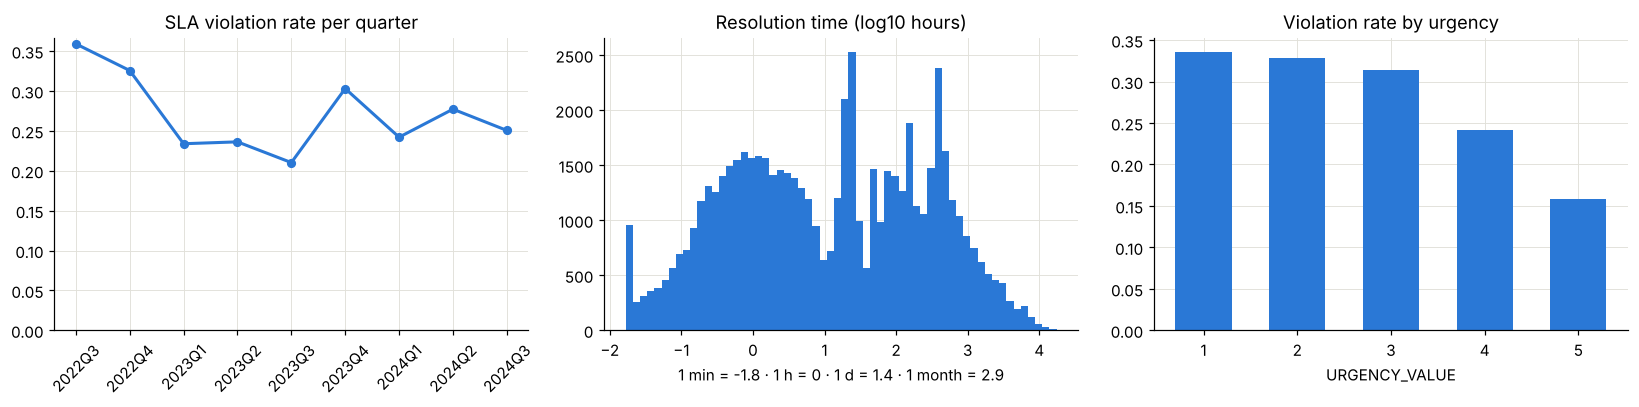

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))

q = df.dropna(subset=["viol"]).groupby(df.SUBMIT_DATE_UT.dt.to_period("Q"))["viol"].mean()
axes[0].plot(q.index.astype(str), q.values, color=BLUE, lw=2, marker="o", ms=5)
axes[0].set_title("SLA violation rate per quarter")
axes[0].set_ylim(0, None); axes[0].tick_params(axis="x", rotation=45)

axes[1].hist(np.log10(df.res_hours.dropna().clip(lower=1/60)), bins=60, color=BLUE)
axes[1].set_title("Resolution time (log10 hours)")
axes[1].set_xlabel("1 min = -1.8 · 1 h = 0 · 1 d = 1.4 · 1 month = 2.9")

u = df.dropna(subset=["viol"]).groupby("URGENCY_VALUE")["viol"].mean()
axes[2].bar(u.index.astype(str), u.values, color=BLUE, width=0.6)
axes[2].set_title("Violation rate by urgency"); axes[2].set_xlabel("URGENCY_VALUE")
plt.tight_layout(); plt.show()